In [101]:
import pandas as pd
import numpy as np

df=pd.read_csv("wdbc.data",names = [
    'id',
    'diagnosis',
    'radius_mean',
    'texture_mean',
    'perimeter_mean',
    'area_mean',
    'smoothness_mean',
    'compactness_mean',
    'concavity_mean',
    'concave points_mean',
    'symmetry_mean',
    'fractal_dimension_mean',
    'radius_se',
    'texture_se',
    'perimeter_se',
    'area_se',
    'smoothness_se',
    'compactness_se',
    'concavity_se',
    'concave points_se',
    'symmetry_se',
    'fractal_dimension_se',
    'radius_worst',
    'texture_worst',
    'perimeter_worst',
    'area_worst',
    'smoothness_worst',
    'compactness_worst',
    'concavity_worst',
    'concave points_worst',
    'symmetry_worst',
    'fractal_dimension_worst'
])

In [102]:

# binary columns
binary_cols = [col for col in df.columns if df[col].nunique() == 2]

# categorical columns
cat_cols = df.select_dtypes(include='object').columns.tolist()

# remove binary from cat
cat_cols = [col for col in cat_cols if col not in binary_cols]

# numeric columns
num_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

print(binary_cols)
print(cat_cols)
print(num_cols)

['diagnosis']
[]
['id', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']


C:\Users\DELL\AppData\Local\Temp\ipykernel_2728\2241880737.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include='object').columns.tolist()


In [103]:
print("before null:",df.isnull().sum().sum())
for col in num_cols:
    df[col]=df[col].fillna(df[col].median())
print("after null handling:", df.isnull().sum().sum())

before null: 0
after null handling: 0


In [104]:
num_cols.remove('id')
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3- Q1
    lower_bound = Q1- 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df=df[df[col].between(lower_bound,upper_bound)]

In [105]:
X=df.drop(columns=['diagnosis'])
y=df['diagnosis']

In [106]:
print(X.columns)

Index(['id', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean',
       'smoothness_mean', 'compactness_mean', 'concavity_mean',
       'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
       'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
       'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se',
       'fractal_dimension_se', 'radius_worst', 'texture_worst',
       'perimeter_worst', 'area_worst', 'smoothness_worst',
       'compactness_worst', 'concavity_worst', 'concave points_worst',
       'symmetry_worst', 'fractal_dimension_worst'],
      dtype='str')


In [107]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.preprocessing import MaxAbsScaler, RobustScaler

X = StandardScaler().fit_transform(df[num_cols])


from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, LabelEncoder
y = LabelEncoder().fit_transform(y)


In [108]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.8, random_state=42, stratify=y)

In [109]:
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

model=DecisionTreeClassifier(
criterion="gini",
max_depth=None,
min_samples_split=0.9,
min_samples_leaf=2,
random_state=42)
model.fit(X_train,y_train)

,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",0.9
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [110]:
from sklearn.model_selection import KFold, cross_val_score, cross_validate,StratifiedKFold

skf=StratifiedKFold(
n_splits=5,
shuffle=True,
random_state=42
)

scores=cross_val_score(model,
X=X_train, y=y_train,
cv=skf, scoring="accuracy")

print(scores)
print(scores.mean())

[0.81818182 0.90909091 0.90909091 0.90909091 0.90909091]
0.8909090909090909


C:\Users\DELL\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


In [111]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

params={"criterion":["gini","entropy"],
"max_depth":[2,3,4,5],
"min_samples_split":[2,3],"min_samples_leaf":[1,2]}

search=RandomizedSearchCV(DecisionTreeClassifier(),
param_distributions=params,
cv=skf,
scoring="accuracy",n_jobs=-1)
search.fit(X_train,y_train)

best=search.best_estimator_
print(search.cv_results_)
print(search.best_score_)

C:\Users\DELL\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


{'mean_fit_time': array([0.00612502, 0.00598969, 0.0055378 , 0.00619421, 0.00648885,
       0.00693321, 0.00816879, 0.00838432, 0.00738306, 0.00728955]), 'std_fit_time': array([0.00044685, 0.00064748, 0.00038153, 0.000281  , 0.00046526,
       0.00228758, 0.00132083, 0.00111786, 0.00118831, 0.00035074]), 'mean_score_time': array([0.00545359, 0.00564528, 0.00564852, 0.00560145, 0.00554876,
       0.00747142, 0.00737066, 0.00658598, 0.00702429, 0.00576396]), 'std_score_time': array([0.00063453, 0.00110421, 0.00090178, 0.00046628, 0.0004945 ,
       0.00234818, 0.0005195 , 0.00063132, 0.00064721, 0.00036592]), 'param_min_samples_split': masked_array(data=[3, 3, 3, 3, 2, 3, 3, 3, 2, 3],
             mask=[False, False, False, False, False, False, False, False,
                   False, False],
       fill_value=999999), 'param_min_samples_leaf': masked_array(data=[2, 1, 1, 1, 1, 2, 1, 2, 1, 2],
             mask=[False, False, False, False, False, False, False, False,
                   Fa

0.9369369369369369
0.9369369369369369
0.6111111111111112
0.6111111111111112
              precision    recall  f1-score   support

           0       0.97      0.97      0.97       204
           1       0.61      0.61      0.61        18

    accuracy                           0.94       222
   macro avg       0.79      0.79      0.79       222
weighted avg       0.94      0.94      0.94       222



<Axes: >

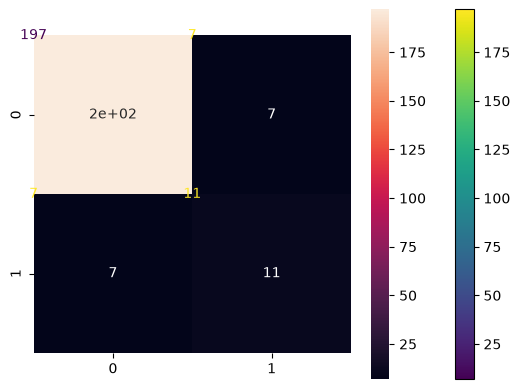

In [112]:
y_pred=best.predict(X_test)

from sklearn.metrics import (
accuracy_score, precision_score, recall_score, f1_score,
confusion_matrix, classification_report, roc_auc_score,
roc_curve, average_precision_score
)
print(accuracy_score(y_test,y_pred))
print(precision_score(y_test,y_pred,average="micro"))
print(recall_score(y_test,y_pred))
print(f1_score(y_test,y_pred))
print(classification_report(y_test,y_pred))
import seaborn as sns
cf=confusion_matrix(y_test,y_pred)
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
sns.heatmap(
cf,
annot=True,
)

In [113]:
print(search.best_estimator_)

DecisionTreeClassifier(criterion='entropy', max_depth=2, min_samples_leaf=2,
                       min_samples_split=3)


In [114]:
#memorise this

for param, value in search.best_params_.items():
    print(param,value)

min_samples_split 3
min_samples_leaf 2
max_depth 2
criterion entropy


In [115]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.8, random_state=42, stratify=y)

from sklearn.decomposition import PCA
pca = PCA(
n_components=0.95,
random_state=42)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)
print(pca.explained_variance_ratio_.sum())
print(pca.singular_values_)
print(X_train.shape[1])
print(X_train_pca.shape[1])

0.9620675439383
[24.18949433 19.96429348 15.00198859 12.25035791  9.38724274  8.18791862
  6.94146818  6.29580515  5.5691434   4.78072647]
30
10


In [116]:
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

model=DecisionTreeClassifier(criterion="gini",max_depth=None,min_samples_split=0.9,min_samples_leaf=2,random_state=42)
model.fit(X_train_pca,y_train)

,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",0.9
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [117]:
from sklearn.model_selection import KFold, cross_val_score, cross_validate,StratifiedKFold
skf=StratifiedKFold(
n_splits=5,
shuffle=True,
random_state=42
)

scores=cross_val_score(DecisionTreeClassifier(),X=X_train_pca, y=y_train,cv=skf, scoring="accuracy")
print(scores)
print(scores.mean())

[0.72727273 0.90909091 0.81818182 0.90909091 0.90909091]
0.8545454545454545


C:\Users\DELL\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


In [118]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

search_pca=RandomizedSearchCV(model,
param_distributions={"criterion":["gini","entropy"],
"max_depth":[2,3,4,5],
"min_samples_split":[2,3],"min_samples_leaf":[1,2]},
 cv=skf, scoring="accuracy", n_jobs=-1)
search_pca.fit(X_train_pca,y_train)

best_pca=search_pca.best_estimator_
print(search_pca.best_score_)
for param,val in search_pca.best_params_.items():
    print(param,val)

C:\Users\DELL\anaconda3\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


0.8909090909090909
min_samples_split 3
min_samples_leaf 2
max_depth 4
criterion gini


0.9369369369369369
0.9369369369369369
0.2777777777777778
0.4166666666666667
              precision    recall  f1-score   support

           0       0.94      1.00      0.97       204
           1       0.83      0.28      0.42        18

    accuracy                           0.94       222
   macro avg       0.89      0.64      0.69       222
weighted avg       0.93      0.94      0.92       222



<Axes: >

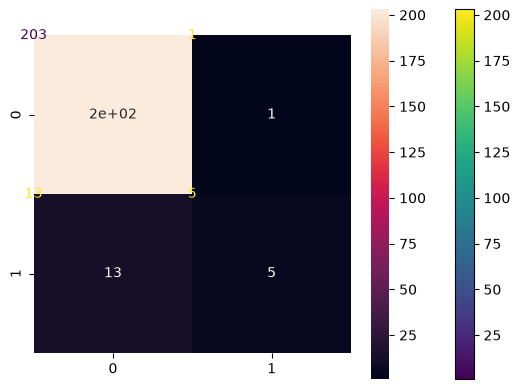

In [122]:
y_pred=best_pca.predict(X_test_pca)

from sklearn.metrics import (
accuracy_score, precision_score, recall_score, f1_score,
confusion_matrix, classification_report, roc_auc_score,
roc_curve, average_precision_score)

print(accuracy_score(y_test,y_pred))
print(precision_score(y_test,y_pred,average="micro"))
print(recall_score(y_test,y_pred))
print(f1_score(y_test,y_pred))
print(classification_report(y_test,y_pred))

import seaborn as sns
cf=confusion_matrix(y_test,y_pred)
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
sns.heatmap(cf,annot=True,)

In [125]:
from scipy.stats import ttest_rel
scores_nopca=[0.72727273 ,0.90909091, 0.81818182 ,0.90909091 ,0.90909091]
scores_withpca=[0.81818182 ,0.90909091 ,0.90909091 ,0.90909091 ,0.90909091]

stat,p_value=ttest_rel(scores_nopca,scores_withpca)
print(p_value)
if p_value<0.05:
    print("significant difference ")
else:
    print("no significant difference")


0.17780780835622137
no significant difference
